# typical imports

In [1]:
import pandas as pd
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
from scipy.stats import shapiro
import numpy as np
from scipy.stats import mannwhitneyu, ks_2samp

# define common functions

In [ ]:
def data_by_cid(df, cid):
    output = df[df["cid"] == cid]

    return output

def hourly_resampling(df):
    df_set_index = df.set_index("cycle_start_time")

    df_set_index = df_set_index.sort_index()

    df_resampled = df_set_index.resample("h").agg({
        "plan_name": "first",  
        "vehicle_count": "sum",    
        "ds": "mean"
    }).reset_index()

    df_resampled = df_resampled.sort_values(by="cycle_start_time", ascending=True)

    df_dropped_NA = df_resampled.dropna()

    return df_dropped_NA

def split_AB_cases(df, split_datetime):
    case_A = df[df["cycle_start_time"] <= split_datetime]
    case_B = df[df["cycle_start_time"] > split_datetime]

    return case_A, case_B

def statistic_result(case_A, case_B, metrics):
    results = {}

    for metric in metrics:
        t_stat, p_value = ttest_ind(case_A[metric], case_B[metric], equal_var=False, alternative="greater")
        results[metric] = {"t_stat": t_stat, "p_value": p_value}

    return results

def test_normality(df, numeric_columns):
    results = []

    for numeric_column in numeric_columns:
        stat, p_value = shapiro(df[numeric_column])
        results.append((numeric_column, stat, p_value))
        
    return results

def non_parametric_tests(case_A, case_B, metrics):
    results = {}
    
    for metric in metrics:
        u_stat, u_p_value = mannwhitneyu(case_A[metric], case_B[metric], alternative='greater')
        
        ks_stat, ks_p_value = ks_2samp(case_A[metric], case_B[metric], alternative='greater')
        
        results[metric] = {
            "mannwhitneyu_stat": u_stat,
            "mannwhitneyu_p_value": u_p_value,
            "ks_stat": ks_stat,
            "ks_p_value": ks_p_value
        }
    
    return results

# load data for particular junction

In [2]:
# load data from CSV
data_source_path = r"C:\Users\Rahman\Downloads\dclp2_data_935_943_961.csv"
all_junctions = pd.read_csv(data_source_path)

In [3]:
all_junctions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730266 entries, 0 to 730265
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   cycle_plan_pk     730266 non-null  int64 
 1   cid               730266 non-null  int64 
 2   plan_name         730266 non-null  object
 3   cycle_length      730266 non-null  int64 
 4   cycle_start_time  730216 non-null  object
 5   stage_name        730266 non-null  object
 6   exec_green        730266 non-null  int64 
 7   detector_name     730266 non-null  object
 8   vehicle_count     730266 non-null  int64 
 9   ds                730266 non-null  int64 
 10  queue             730266 non-null  int64 
dtypes: int64(7), object(4)
memory usage: 61.3+ MB


In [4]:
all_junctions

,cycle_plan_pk,cid,plan_name,cycle_length,cycle_start_time,stage_name,exec_green,detector_name,vehicle_count,ds,queue
0,5989447,943,PLN03,177,2024-11-26 11:50:04,STG03,28,V6,6,62,42
1,5989899,943,PLN03,176,2024-11-26 11:58:45,STG01,80,V4,2,19,11
2,5992803,943,PLN03,178,2024-11-26 12:54:01,STG02,44,V3,13,31,14
3,5992803,943,PLN03,178,2024-11-26 12:54:01,STG02,44,V4,6,14,7
4,5992803,943,PLN03,178,2024-11-26 12:54:01,STG02,44,V5,8,35,22
...,...,...,...,...,...,...,...,...,...,...,...
730261,5985658,935,PLN03,175,2024-11-26 10:36:40,STG02,96,V2,7,23,13
730262,5985658,935,PLN03,175,2024-11-26 10:36:40,STG02,96,V3,24,34,14
730263,5985658,935,PLN03,175,2024-11-26 10:36:40,STG02,96,V4,18,23,10
730264,5985866,943,PLN03,168,2024-11-26 10:40:38,STG03,28,V6,10,52,35


In [5]:
# convert "cycle_start_time" to pandas datetime
all_junctions["cycle_start_time"] = pd.to_datetime(
    all_junctions["cycle_start_time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="raise"
)

# define split datetime for AB test

In [7]:
# define split datetime
split_datetime = pd.Timestamp("2024-11-11 23:59:59")

# define metrics/KPI we want to do A-B test on
metrics = ["exec_green", "veh_count", "ds", "queue"]

# analysis per junction

## filter for 935
## resample to hourly

In [14]:
df_935 = data_by_cid(all_junctions, 935)
df_935_hourly = hourly_resampling(df_935)

In [18]:
df_935_A, df_935_B = split_AB_cases(df_935_hourly, split_datetime)

## also segregate by plans for A and B cases

In [23]:
df_935_A.info()

<class 'pandas.core.frame.DataFrame'>
Index: 768 entries, 0 to 866
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   cycle_start_time  768 non-null    datetime64[ns]
 1   plan_name         768 non-null    object        
 2   vehicle_count     768 non-null    int64         
 3   ds                768 non-null    float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 30.0+ KB


In [24]:
df_935_A

,cycle_start_time,plan_name,vehicle_count,ds
0,2024-10-06 21:00:00,PLN03,54,24.000000
90,2024-10-10 15:00:00,PLN02,14,55.600000
96,2024-10-10 21:00:00,PLNPP,41,37.111111
98,2024-10-10 23:00:00,PLN01,3,5.000000
99,2024-10-11 00:00:00,PLN01,412,8.365759
...,...,...,...,...
862,2024-11-11 19:00:00,PLN04,909,32.855856
863,2024-11-11 20:00:00,PLN04,736,24.689655
864,2024-11-11 21:00:00,PLN04,788,22.923077
865,2024-11-11 22:00:00,PLN06,792,16.726872


In [25]:
df_935_A['hour'] = df_935_A['cycle_start_time'].dt.hour

# Group by 'plan_name' and aggregate the min and max hour
result = df_935_A.groupby('plan_name')['hour'].agg(['min', 'max']).reset_index()

C:\Users\Rahman\AppData\Local\Temp\ipykernel_35784\742860070.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_935_A['hour'] = df_935_A['cycle_start_time'].dt.hour


In [26]:
result

,plan_name,min,max
0,PLN01,0,23
1,PLN02,7,15
2,PLN03,8,21
3,PLN04,16,21
4,PLN05,8,21
5,PLN06,0,23
6,PLNAP,7,9
7,PLNPP,16,21


In [28]:
df_935_B['hour'] = df_935_B['cycle_start_time'].dt.hour

# Group by 'plan_name' and aggregate the min and max hour
result1 = df_935_B.groupby('plan_name')['hour'].agg(['min', 'max']).reset_index()

C:\Users\Rahman\AppData\Local\Temp\ipykernel_35784\4084226786.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_935_B['hour'] = df_935_B['cycle_start_time'].dt.hour


In [ ]:
result1

,plan_name,min,max
0,PLN01,0,6
1,PLN02,7,10
2,PLN03,11,16
3,PLN04,16,23
4,PLN05,8,21
5,PLN06,0,23


possible comparison
- PLNAP -> PLN02
- PLNPP -> PLN04

# A (PLNAP) | B (PLN02)

In [35]:
case_A_PLNAP = df_935_A[df_935_A['plan_name'] == 'PLNAP']

In [39]:
case_A_PLNAP.describe()

,cycle_start_time,vehicle_count,ds
count,60,60.000000,60.000000
mean,2024-10-25 10:24:00,1184.466667,32.299022
min,2024-10-11 07:00:00,29.000000,13.222222
25%,2024-10-18 01:30:00,1131.250000,31.510975
50%,2024-10-24 20:00:00,1258.000000,33.344335
75%,2024-10-31 14:30:00,1375.000000,34.312961
max,2024-11-07 09:00:00,1527.000000,44.644628
std,NaN,291.968101,4.696973


In [48]:
case_A_PLNAP.head()

,cycle_start_time,plan_name,vehicle_count,ds
106,2024-10-11 07:00:00,PLNAP,1379,31.726562
107,2024-10-11 08:00:00,PLNAP,1261,38.440367
108,2024-10-11 09:00:00,PLNAP,1149,34.078261
178,2024-10-14 07:00:00,PLNAP,1261,31.762295
179,2024-10-14 08:00:00,PLNAP,1146,32.933884


In [43]:
case_B_PLN02 = df_935_B[df_935_B['plan_name'] == 'PLN02']

In [45]:
case_B_PLN02.describe()

,cycle_start_time,vehicle_count,ds
count,40,40.000000,40.000000
mean,2024-11-20 08:03:00,1004.650000,32.406529
min,2024-11-12 07:00:00,600.000000,30.275000
25%,2024-11-15 07:45:00,852.750000,31.706814
50%,2024-11-20 08:30:00,1054.500000,32.253361
75%,2024-11-25 08:15:00,1131.250000,33.092484
max,2024-11-28 09:00:00,1422.000000,35.858333
std,NaN,184.823901,1.159319


In [47]:
case_B_PLN02.head()

,cycle_start_time,plan_name,vehicle_count,ds
874,2024-11-12 07:00:00,PLN02,1422,33.259843
875,2024-11-12 08:00:00,PLN02,1149,32.293103
876,2024-11-12 09:00:00,PLN02,1084,30.568807
898,2024-11-13 07:00:00,PLN02,932,34.025862
899,2024-11-13 08:00:00,PLN02,793,32.576000


In [52]:
test_normality(case_A_PLNAP, ["ds", "vehicle_count"], "935 Case A PLNAP")

Normality Test Results for 935 Case A PLNAP:

ds          : W-stat=0.7975, p-value=0.0000 -> Not Normal
vehicle_count: W-stat=0.8098, p-value=0.0000 -> Not Normal




[('ds', 0.7974900424587849, 1.1696644374795572e-07),
 ('vehicle_count', 0.8098355919126133, 2.3948664412700463e-07)]

In [53]:
test_normality(case_B_PLN02, ["ds", "vehicle_count"], "935 Case B PLN02")

Normality Test Results for 935 Case B PLN02:

ds          : W-stat=0.9605, p-value=0.1744 -> Normal
vehicle_count: W-stat=0.9630, p-value=0.2121 -> Normal




[('ds', 0.960515893970199, 0.17443568916877372),
 ('vehicle_count', 0.9630160589069965, 0.212110342051887)]

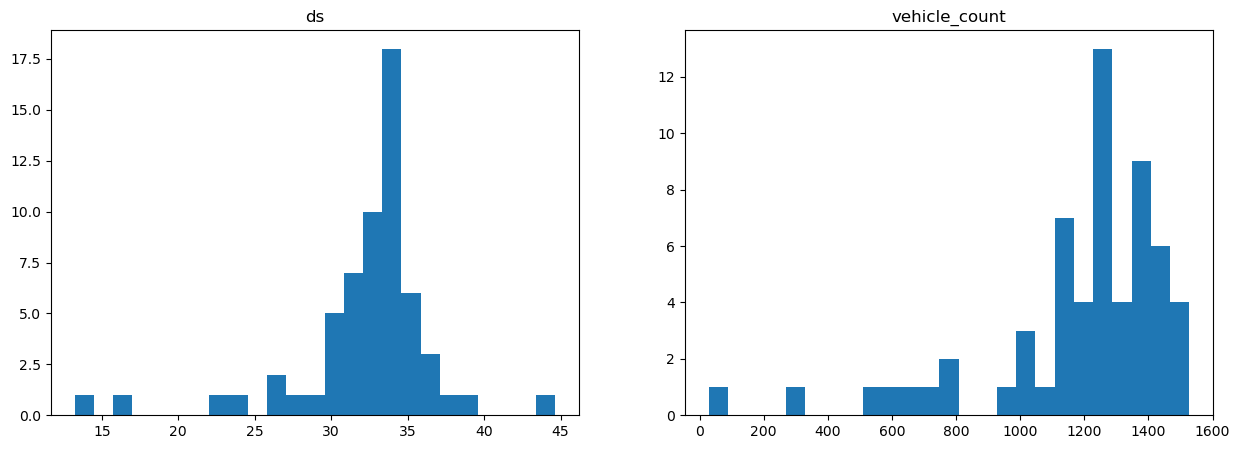

In [60]:
# plot histogram for "ds", "ds_sqrt", "ds_log" columns
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].hist(case_A_PLNAP["ds"], bins=25)
ax[0].set_title("ds")

ax[1].hist(case_A_PLNAP["vehicle_count"], bins=25)
ax[1].set_title("vehicle_count")

plt.show()

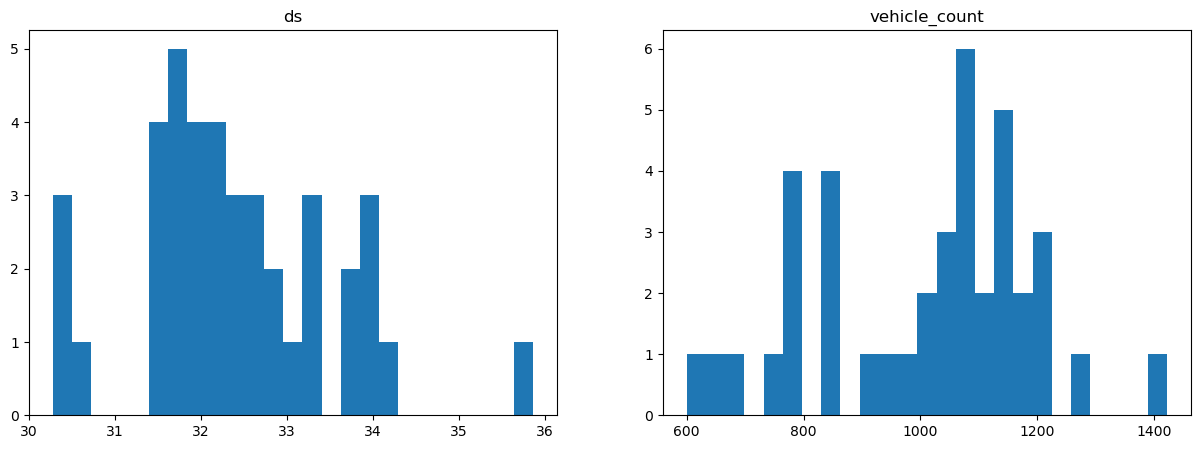

In [61]:
# plot histogram for "ds", "ds_sqrt", "ds_log" columns
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].hist(case_B_PLN02["ds"], bins=25)
ax[0].set_title("ds")

ax[1].hist(case_B_PLN02["vehicle_count"], bins=25)
ax[1].set_title("vehicle_count")

plt.show()

In [62]:
statistic_result(case_A_PLNAP, case_B_PLN02, ["ds", "vehicle_count"])

{'ds': {'t_stat': -0.16970970531458804, 'p_value': 0.5671339097548496},
 'vehicle_count': {'t_stat': 3.770186328508011,
  'p_value': 0.00013962559842670038}}

## possible normalizing transform if original data is not normally distributed

In [10]:
# either one or both?
df_935_hourly["ds_sqrt"] = np.sqrt(df_935_hourly['ds'])
df_935_hourly["ds_log"] = np.log1p(df_935_hourly['ds'])

In [21]:
# Define metrics to test
metrics = ["ds", "ds_sqrt", "ds_log"]

# Perform the non-parametric tests
results = non_parametric_tests(df_935_A, df_935_B, metrics)

# Print results in a readable format
for metric, stat in results.items():
    print(f"Metric: {metric}")
    print(f"  Mann-Whitney U Test: U-Stat={stat['mannwhitneyu_stat']:.4f}, P-Value={stat['mannwhitneyu_p_value']:.4e}")
    print(f"  Kolmogorov-Smirnov Test: KS-Stat={stat['ks_stat']:.4f}, P-Value={stat['ks_p_value']:.4e}")
    print()


Metric: ds
  Mann-Whitney U Test: U-Stat=144727.5000, P-Value=1.6040e-02
  Kolmogorov-Smirnov Test: KS-Stat=0.0231, P-Value=7.5897e-01

Metric: ds_sqrt
  Mann-Whitney U Test: U-Stat=144727.5000, P-Value=1.6040e-02
  Kolmogorov-Smirnov Test: KS-Stat=0.0231, P-Value=7.5897e-01

Metric: ds_log
  Mann-Whitney U Test: U-Stat=144727.5000, P-Value=1.6040e-02
  Kolmogorov-Smirnov Test: KS-Stat=0.0231, P-Value=7.5897e-01

